In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
%matplotlib inline
plt.rc("font", size=15)
plt.rc("axes", titlesize=15)
plt.rc("xtick", labelsize=15)
plt.rc("ytick", labelsize=15)
plt.rc("legend", fontsize=15)
plt.rc("axes", labelsize=20)
plt.rc("figure", titlesize=40)

plt.rcParams['xtick.labelsize'] = plt.rcParams['ytick.labelsize'] = 15

# Input File
Load the input file and extract values

In [2]:
input_file="InputFiles/elliptical_E.txt"

In [3]:
#find R_s from inputs file
data = np.genfromtxt(input_file,comments="//",max_rows=5, usecols=2, unpack=True)
R_s = data[4]

#open file for further inputs
data = np.genfromtxt(input_file,comments="//",skip_header=10, usecols=2, unpack=True)
init_r = data[2]

#open file in way to read strings
file = open(input_file)
file_stream = file.readlines()
output_dir = file_stream[11][13:-1]
#check type and load phi if file has it
if file_stream[7][14:] == "Input 2D":
    init_phi = data[4]

## Plotting Orbits

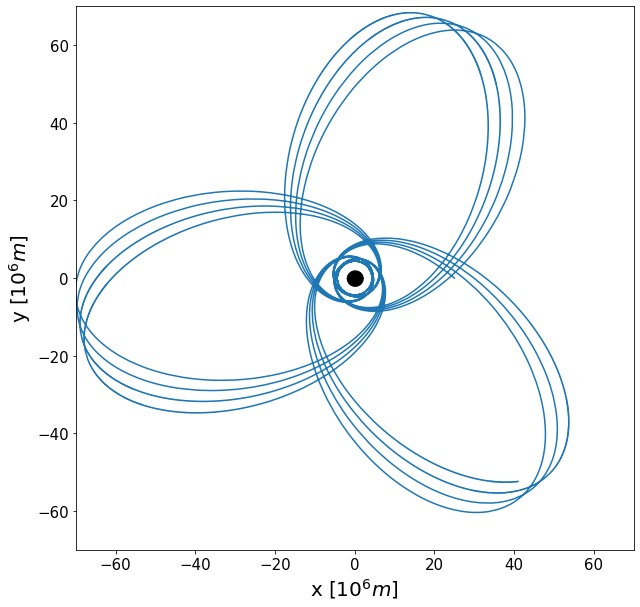

In [10]:
data = np.genfromtxt(output_dir, unpack=True)
time_abs, time, time_vel, rad, rad_vel, phi, phi_vel = data

fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot()

xs = rad * np.cos(phi)
ys = rad * np.sin(phi)

angles = np.linspace(0, 2*3.14159, 100)
hole_xs = R_s * np.cos(angles)
hole_ys = R_s * np.sin(angles)


ax.fill_between(hole_xs, hole_ys, color="black")
ax.plot(xs, ys)

ax.set_xlim(-70,70)
ax.set_ylim(-70,70)

ax.set_xlabel("x [$10^6 m$]")
ax.set_ylabel("y [$10^6 m$]")

os.makedirs("figures", exist_ok = True)
fig.savefig(f"figures/Orbits_Visual_R={R_s}_r={init_r}_u={rad_vel[0]}_w={phi_vel[0]}.png", dpi=300)

# Validation

### Keplers $3^{rd}$ Law
Check that the output follows Kepler's Third Law by creating a plot of $P^2$ against $a^3$ using the equation:
\begin{equation}
P^2 = \frac{4 \pi^2}{G M}a^3
\end{equation}
which, to allow for the use of $R_s$, can be written as:

\begin{equation}
P^2 = \frac{8 \pi^2}{R_s  c^2}a^3
\end{equation}

In [5]:
def calculatePeriod(times, phi):
    #make theta between [0, 2*pi]
    phi_loop = np.mod(phi, 2*np.pi)
    
    #find every point in the data where a full loop happens
    loops = np.where(np.diff(phi_loop) < 0)[0]
    
    #check to make sure full period is complete
    if len(loops) < 2:
        print("A full period was not completed or failed to be found")
        return None

    #find the final period by looking over how many periods have existed
    period = times[loops[len(loops)-1]]/len(loops)
    return period

In [6]:
#load file and output period for it
data = np.genfromtxt(output_dir, unpack=True)
time_abs, time, time_vel, rad, rad_vel, phi, phi_vel = data

calculatePeriod(time, phi)

1.7206833333333333

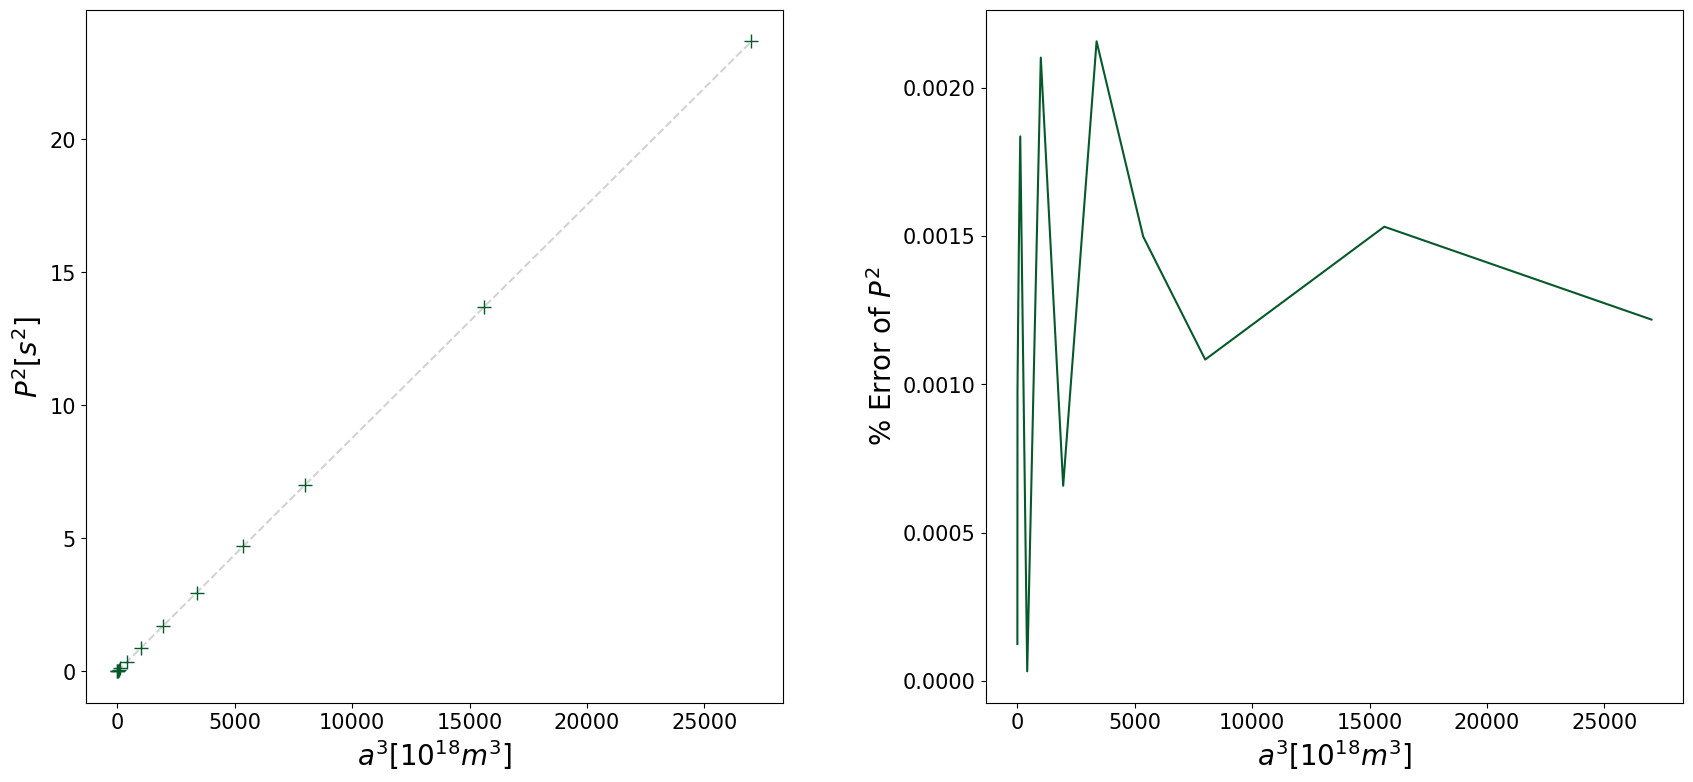

In [14]:
data_radii = np.array([1.5, 2, 3, 4, 5, 7.5, 10, 12.5, 15, 17.5, 20, 25, 30])
data_period = np.array([0.05441394680086269, 0.08377539479746994, 0.15390509360034826, 0.23695204196328212, 0.3311499030202272, 
                        0.6083669025585193, 0.9366321243523316,  1.308992628992629, 1.720702614379085, 
                        2.168340248962656, 2.6492091836734692, 3.7023741007194246, 4.866904761904761])


fig = plt.figure(figsize=(18,9))
figs = fig.subfigures(1, 2)
ax = figs[0].add_subplot()

model_xs = pow(data_radii, 3)
model_ys = 8*np.pi*np.pi/(R_s*90000) * model_xs

ax.plot(model_xs, model_ys, color="lightgray", linestyle="--")
ax.plot(model_xs, pow(data_period,2),marker="+",markersize=10, color= "#06592A",linestyle = " ")
ax.set_xlabel("$a^3 [10^{18} m^3]$")
ax.set_ylabel("$P^2 [s^2]$")

err_ax = figs[1].add_subplot()
err_ax.plot(model_xs, abs(100*(pow(data_period,2)-model_ys)/model_ys), color= "#06592A")
err_ax.set_xlabel("$a^3 [10^{18} m^3]$")
err_ax.set_ylabel("% Error of $P^2$")

os.makedirs("figures/validation", exist_ok = True)
fig.savefig("figures/validation/Keplers_3rd.png", dpi=300)

### Newton 
Check that that the acceleration fits the equation:
\begin{equation}
a=\frac{GM}{r^2}
\end{equation}

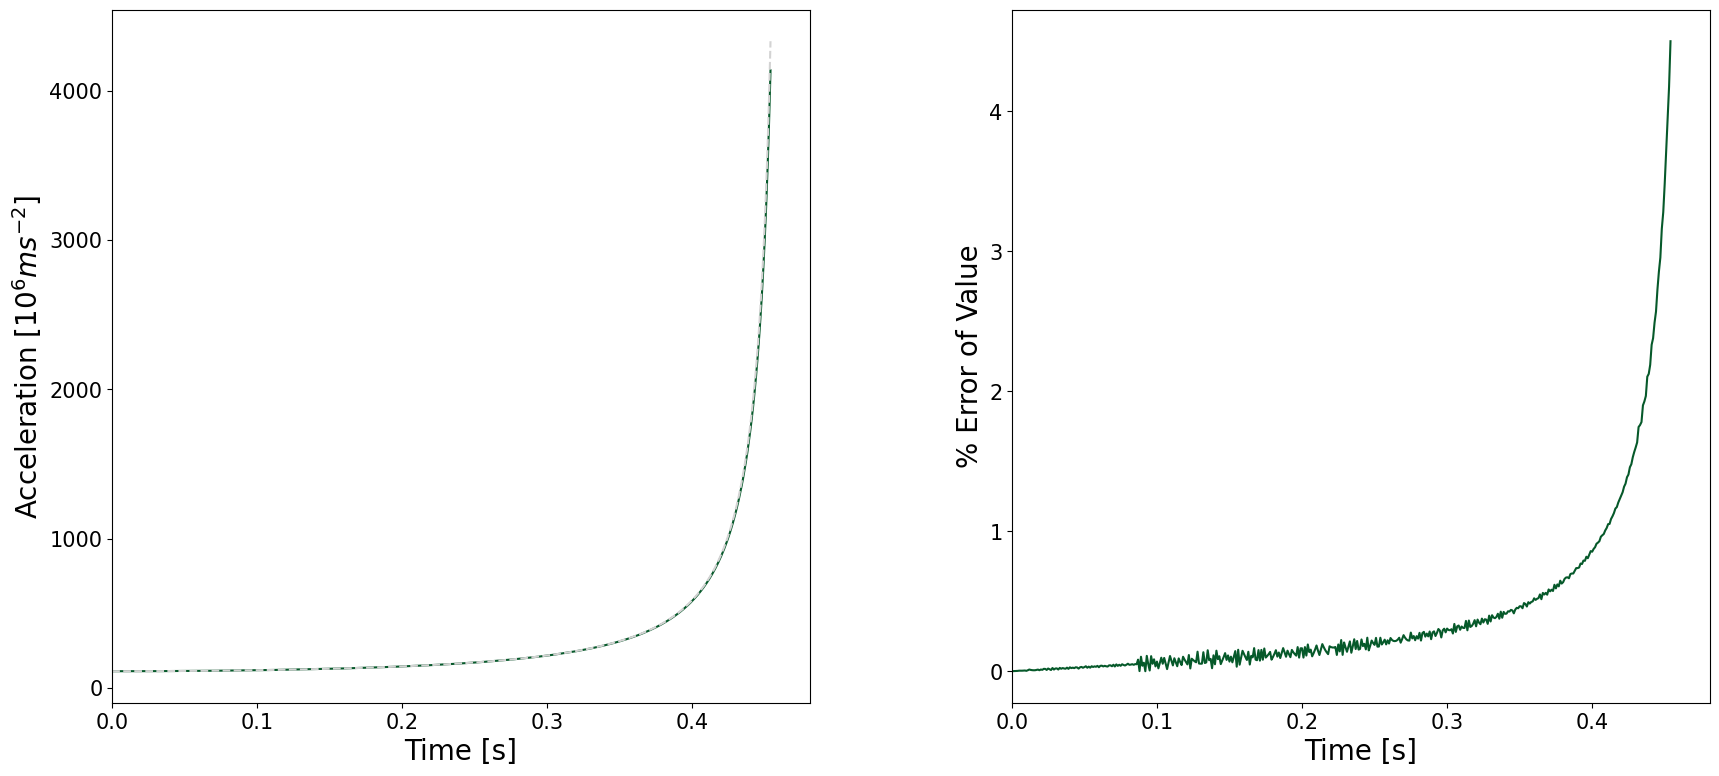

In [18]:
data = np.genfromtxt(output_dir, unpack=True)
time_abs, time, time_vel, rad, rad_vel, phi, phi_vel = data

a_constant = R_s * 9e4 / 2

lengths = np.where(rad <= 3 * R_s)[0]
if len(lengths) > 0:
    length = lengths[0] - 2
else:
    length = len(time_abs) - 1

a_calc_vals = np.zeros(length)
a_vals = np.zeros(length)
for i in range(1, length+1):
    a_vals[i-1] = a_constant/(rad[i]*rad[i])
    
    a_calc_vals[i-1] = (rad_vel[i-1]-rad_vel[i])/(time_abs[i]-time_abs[i-1])

fig = plt.figure(figsize=(18,9))
figs = fig.subfigures(1, 2)
ax = figs[0].add_subplot()

err_ax = figs[1].add_subplot() 

ax.set_xlim(0, time[length])
err_ax.set_xlim(0, time[length])

ax.plot(time_abs[0:length], a_calc_vals, color = "#06592A")
ax.plot(time_abs[0:length], a_vals, color="lightgray", linestyle="--")

err_ax.plot(time_abs[0:length], 100*abs(a_calc_vals-a_vals)/a_vals, color="#06592A")

ax.set_xlabel("Time [s]")
ax.set_ylabel("Acceleration [$10^6ms^{-2}$]")

err_ax.set_xlabel("Time [s]")
err_ax.set_ylabel("% Error of Value")

os.makedirs("figures/validation", exist_ok = True)
fig.savefig("figures/validation/Newtonian Acceleration.png", dpi=300)

### Invarient Quantity

Check that the output follows the invarient quantity by creating a plot of the sum and comparing it to the $c^2$ that it should sum to:
\begin{equation}
\sum_{\mu=0}^{3}\sum_{\nu=0}^{3}g_{\mu \nu}U^\mu U^\nu=c^2
\end{equation}

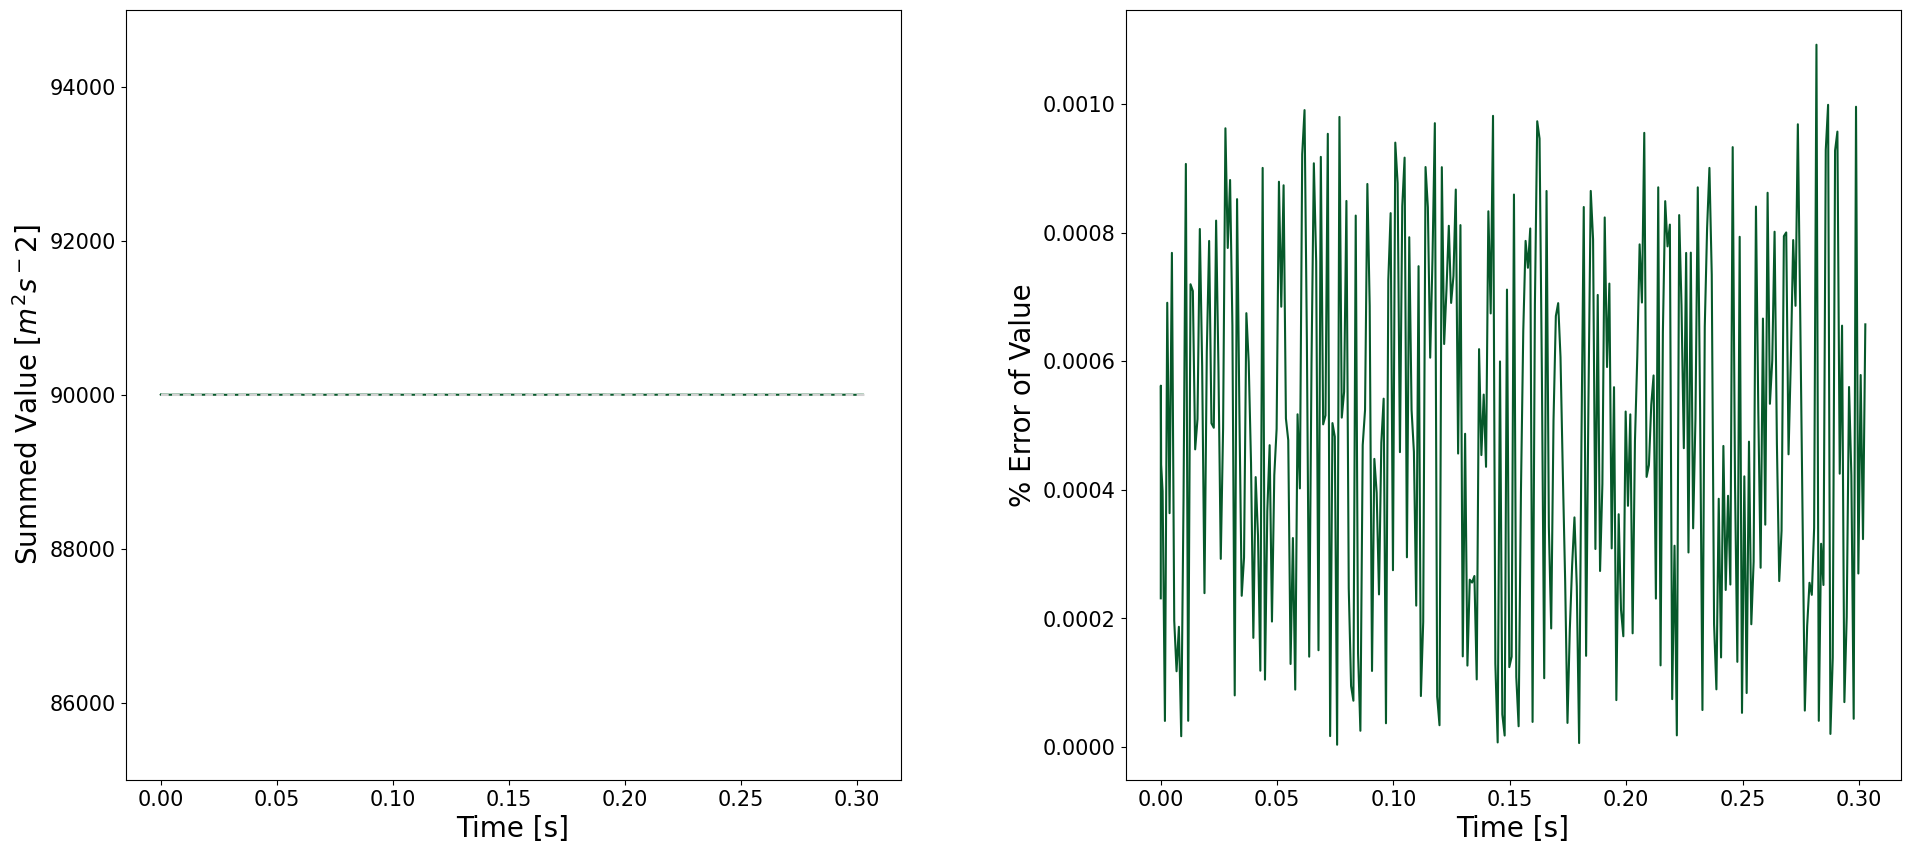

In [7]:
data = np.genfromtxt(output_dir, unpack=True)
time_abs, time, time_vel, rad, rad_vel, phi, phi_vel = data

lengths = np.where(rad <= 3 * R_s)[0]
if len(lengths) > 0:
    length = lengths[0] - 1
else:
    length = len(time) - 1


U_summed = np.zeros(length)
for i in range(length):
    g = [1-(R_s/rad[i]), -1/(1-(R_s/rad[i])), -(rad[i]*rad[i])]     #in t, r, phi as no theta component
    
    U_summed[i] = g[0] * 9e4 * pow(time_vel[i], 2) + g[1] * pow(rad_vel[i], 2) + g[2] * pow(phi_vel[i], 2)
    
fig = plt.figure(figsize=(20,10))
figs = fig.subfigures(1, 2)
ax = figs[0].add_subplot()
err_ax = figs[1].add_subplot()

ax.plot(time_abs[0:length], U_summed, color= "#06592A", label="Data")
ax.plot([0,time_abs[length]], [9e4, 9e4], label="Target", linestyle="--", color="lightgray")
ax.set_ylim(8.5e4, 9.5e4)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Summed Value [$m^2s^-2$]")

err_ax.plot(time_abs[0:length], 100*abs(U_summed - 9e4)/ 9e4, color= "#06592A")
err_ax.set_xlabel("Time [s]")
err_ax.set_ylabel("% Error of Value")
err_ax.ticklabel_format(style="sci", useOffset=False, axis="y")

os.makedirs("figures/validation", exist_ok = True)
fig.savefig("figures/validation/Invarient Quantity.png", dpi=300)

### Energy Conservation

Check that the output follows the conservation of momentum by creating a plot of the sum:
\begin{equation}
\left(1-\frac{R_s}{r}\right)\frac{dx^0}{ds} = \frac{E}{mc^2}
\end{equation}

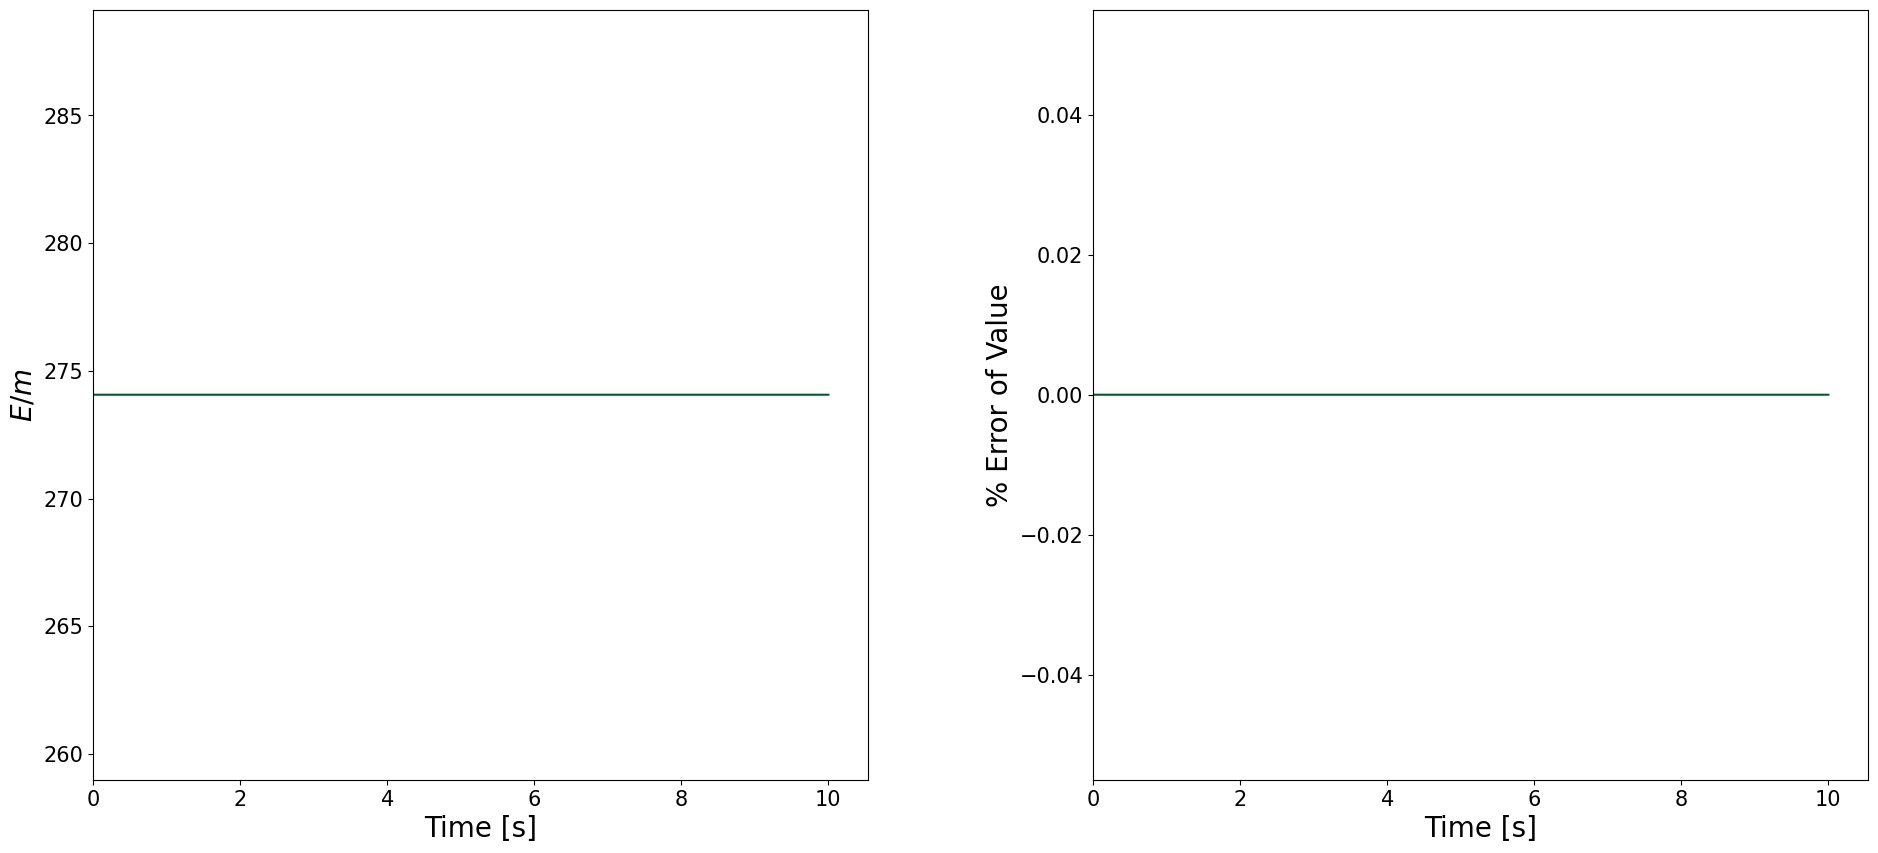

In [15]:
data = np.genfromtxt("output_data.txt", unpack=True)
time_abs, time, time_vel, rad, rad_vel, phi, phi_vel = data

a_constant = R_s * 9e4 / 2

lengths = np.where(rad <= 3 * R_s)[0]
if len(lengths) > 0:
    length = lengths[0] - 1
else:
    length = len(time) - 2

E_calc_vals = np.zeros(length)
for i in range(1, length+1):
   E_calc_vals[i-1] = (1-R_s/rad[i-1])*(300*(time_vel[i-1]))

fig = plt.figure(figsize=(20,10))
figs = fig.subfigures(1, 2)
ax = figs[0].add_subplot()
err_ax = figs[1].add_subplot() 

ax.set_xlim(0, time[length])
err_ax.set_xlim(0, time[length])

ax.plot(time_abs[0:length], E_calc_vals, color = "#06592A")

err_ax.plot(time_abs[0:length], (100*(E_calc_vals-np.average(E_calc_vals))/np.average(E_calc_vals))[0:length], color="#06592A")

ax.set_xlabel("Time [s]")
ax.set_ylabel("$E/m$")

err_ax.set_xlabel("Time [s]")
err_ax.set_ylabel("% Error of Value")

os.makedirs("figures/validation", exist_ok = True)
fig.savefig("figures/validation/Energy_Conservation.png", dpi=300)

### Momentum Conservation

Check that the output follows the conservation of momentum by creating a plot of the sum:
\begin{equation}
r^2\frac{dx^3}{ds} = \frac{L}{mc}
\end{equation}

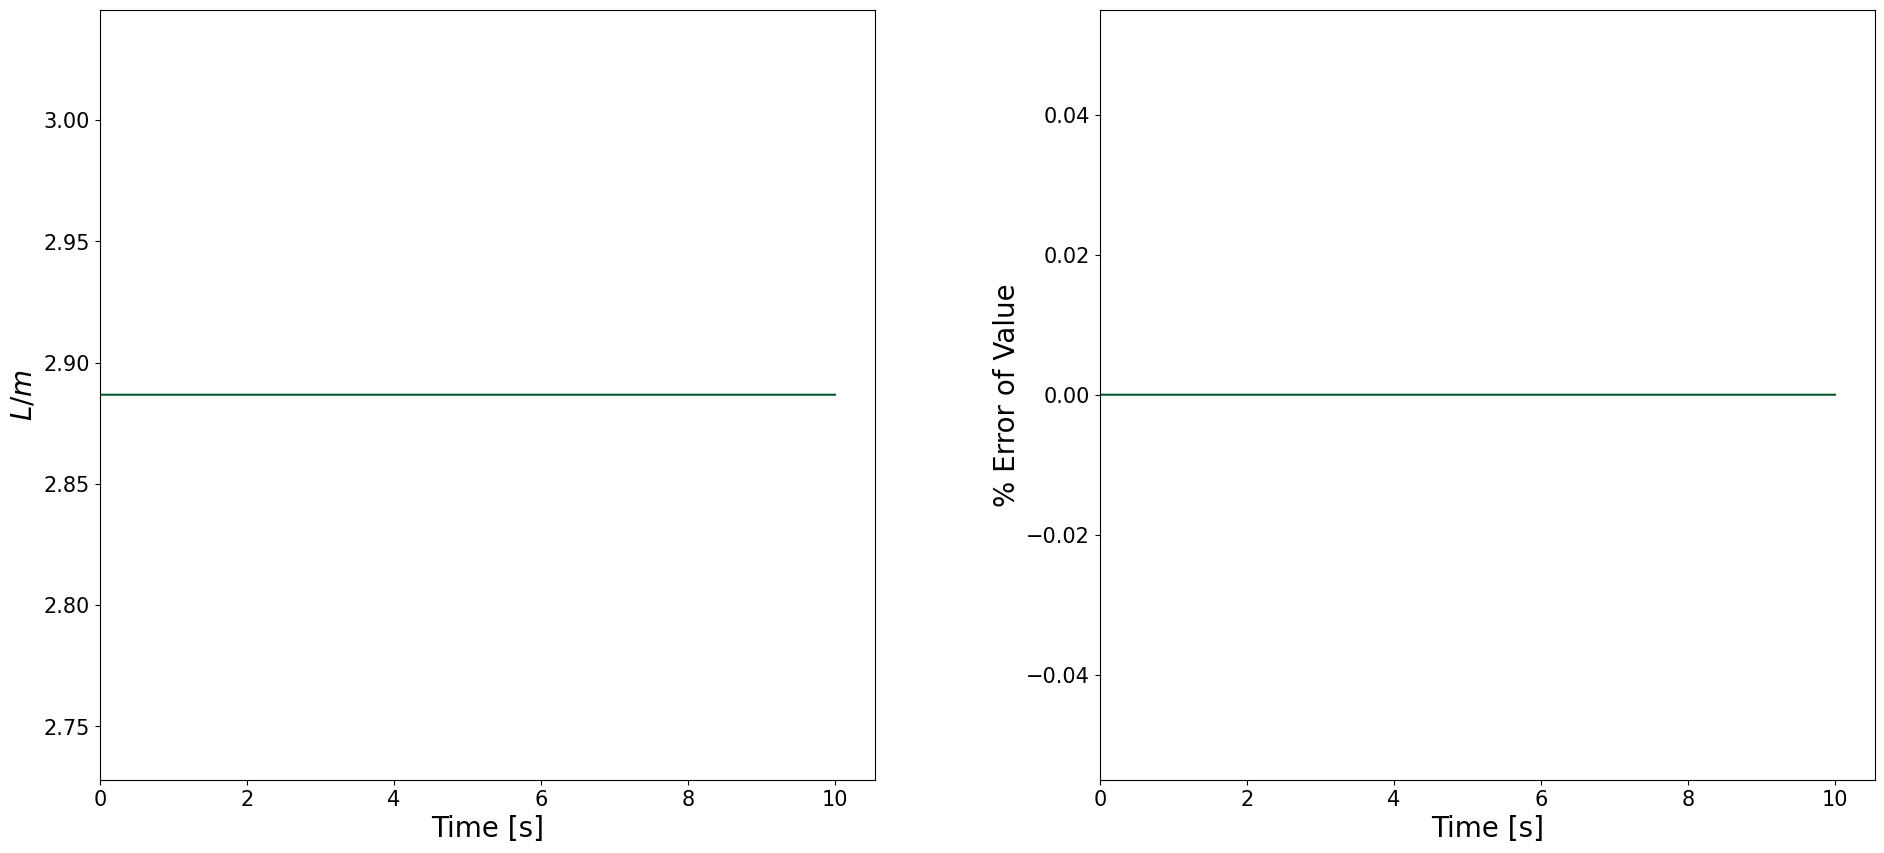

In [13]:
data = np.genfromtxt("output_data.txt", unpack=True)
time_abs, time, time_vel, rad, rad_vel, phi, phi_vel = data

a_constant = R_s * 9e4 / 2

lengths = np.where(rad <= 3 * R_s)[0]
if len(lengths) > 0:
    length = lengths[0] - 1
else:
    length = len(time) - 2

L_calc_vals = np.zeros(length)
for i in range(1, length+1):
   L_calc_vals[i-1] = rad[i-1]*rad[i-1]*(phi_vel[i-1])/300

fig = plt.figure(figsize=(20,10))
figs = fig.subfigures(1, 2)
ax = figs[0].add_subplot()
err_ax = figs[1].add_subplot() 

ax.set_xlim(0, time[length])
err_ax.set_xlim(0, time[length])

ax.plot(time_abs[0:length], L_calc_vals, color = "#06592A")

err_ax.plot(time_abs[0:length], (100*(L_calc_vals-np.average(L_calc_vals))/np.average(L_calc_vals))[0:length], color="#06592A")

ax.set_xlabel("Time [s]")
ax.set_ylabel("$L/m$")

err_ax.set_xlabel("Time [s]")
err_ax.set_ylabel("% Error of Value")

os.makedirs("figures/validation", exist_ok = True)
fig.savefig("figures/validation/Momentum_Conservation.png", dpi=300)